# Lab work 1
### Acoustic scattering in maze-like structures
##### Author: Fedor Sobolevsky

In [1]:
from plotting_setup import configure_matplotlib
configure_matplotlib()

import matplotlib.pyplot as plt

from acoustic_scattering_maze_graph import build_acoustic_scattering_maze_graph
from graph_builder import visualize_graph
from load_and_solve import load_sample, solve_sample
from metrics import relative_l2_error
from visualization import plot_dashboard, plot_fields_grid

import logging

# Configure only the relevant loggers; preserve the notebook's root handlers.
for name in ("clawpack", "CLAW", "httpx", "httpcore", "huggingface_hub"):
    logging.getLogger(name).setLevel(logging.WARNING)


Acoustic scattering equations:
\begin{align}
\frac{\partial p}{\partial t} + K(x,y) \left( \frac{\partial u}{\partial x} + \frac{\partial v}{\partial y} \right) &= 0 \\[6pt]
\frac{\partial u}{\partial t} + \frac{1}{\rho(x,y)} \frac{\partial p}{\partial x} &= 0 \\[6pt]
\frac{\partial v}{\partial t} + \frac{1}{\rho(x,y)} \frac{\partial p}{\partial y} &= 0
\end{align}
Corresponding computational DAG:

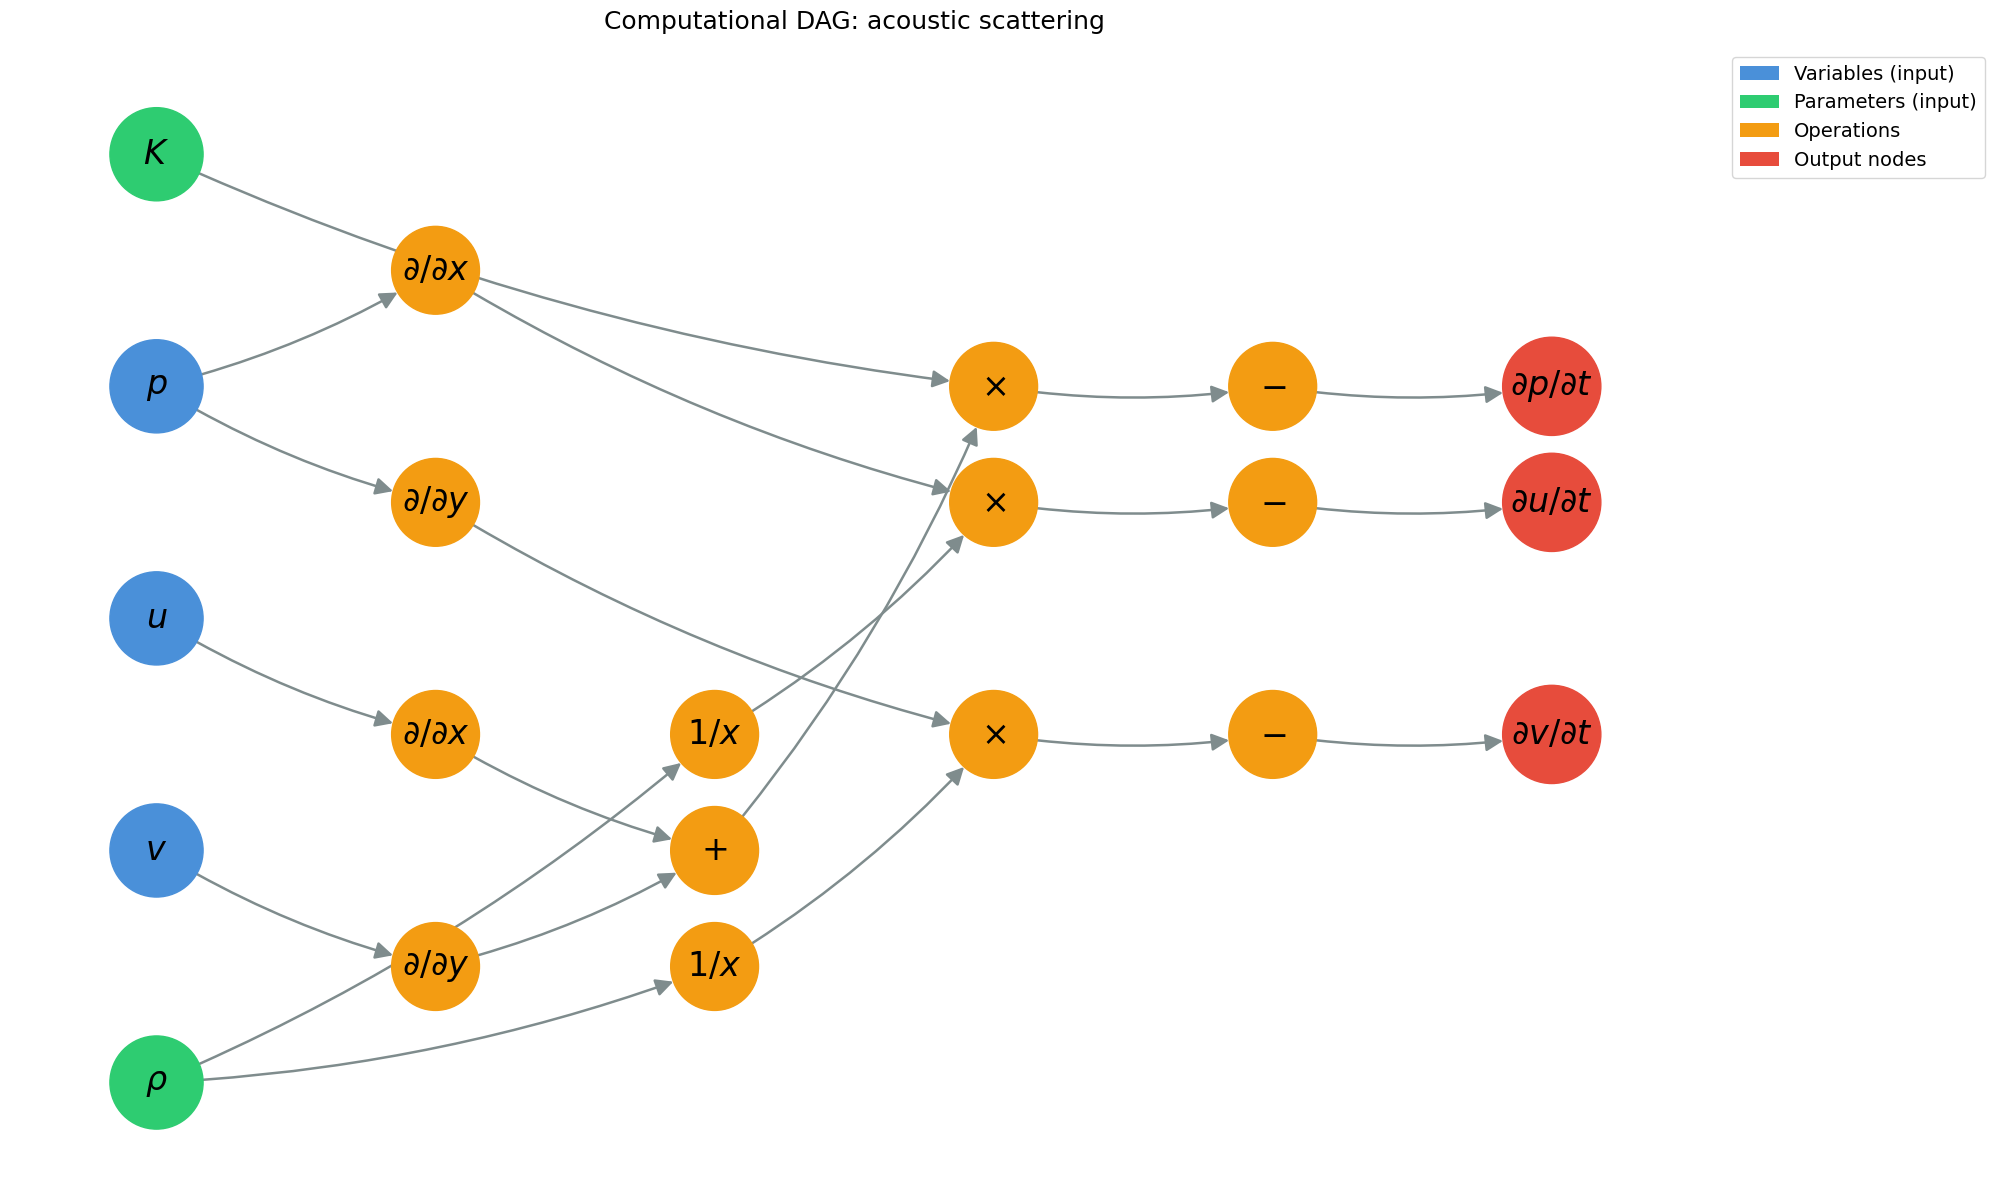

In [2]:
G = build_acoustic_scattering_maze_graph()
fig = visualize_graph(G, title="Computational DAG: acoustic scattering")
plt.show()


## Data and results

[The Well maze dataset](https://polymathic-ai.org/the_well/datasets/acoustic_scattering_maze/) describes acoustic waves propagating through a two-dimensional maze. High-density walls scatter the waves; the plots below show the maze and the initial and final pressure fields.

The numerical solution is compared with the reference pressure at the same times. The final plots show both solutions, their difference, and the relative L2 error over time.

The baseline follows the [generation code](https://github.com/PolymathicAI/the_well/blob/master/datasets/acoustic_scattering_maze/generation/acoustics_2d_interface_maze.py): a $256\times256$ finite-volume grid on $[-1,1]^2$ ($\Delta x=\Delta y=2/256$), reflective lower boundaries and open upper boundaries on both axes, and the classic unsplit MC scheme with target CFL 0.9. The exported 0–1 coordinates are rescaled labels, not physical cell centers. We retain the file’s timestamps and material fields ($K=\rho c^2\approx4$).


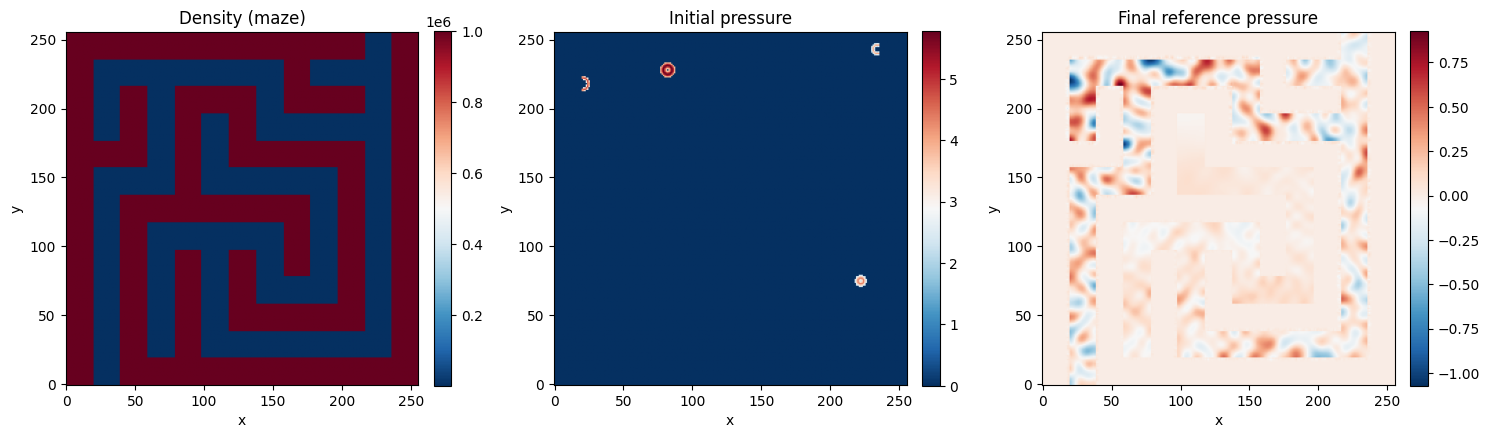

In [3]:
sample = load_sample(sample_idx=0, split="train")
fig = plot_fields_grid(
    [sample["rho"], sample["p0"], sample["p_ref"][-1]],
    titles=["Density (maze)", "Initial pressure", "Final reference pressure"],
)
plt.show()


Final pressure relative L2 error: 0.0474834


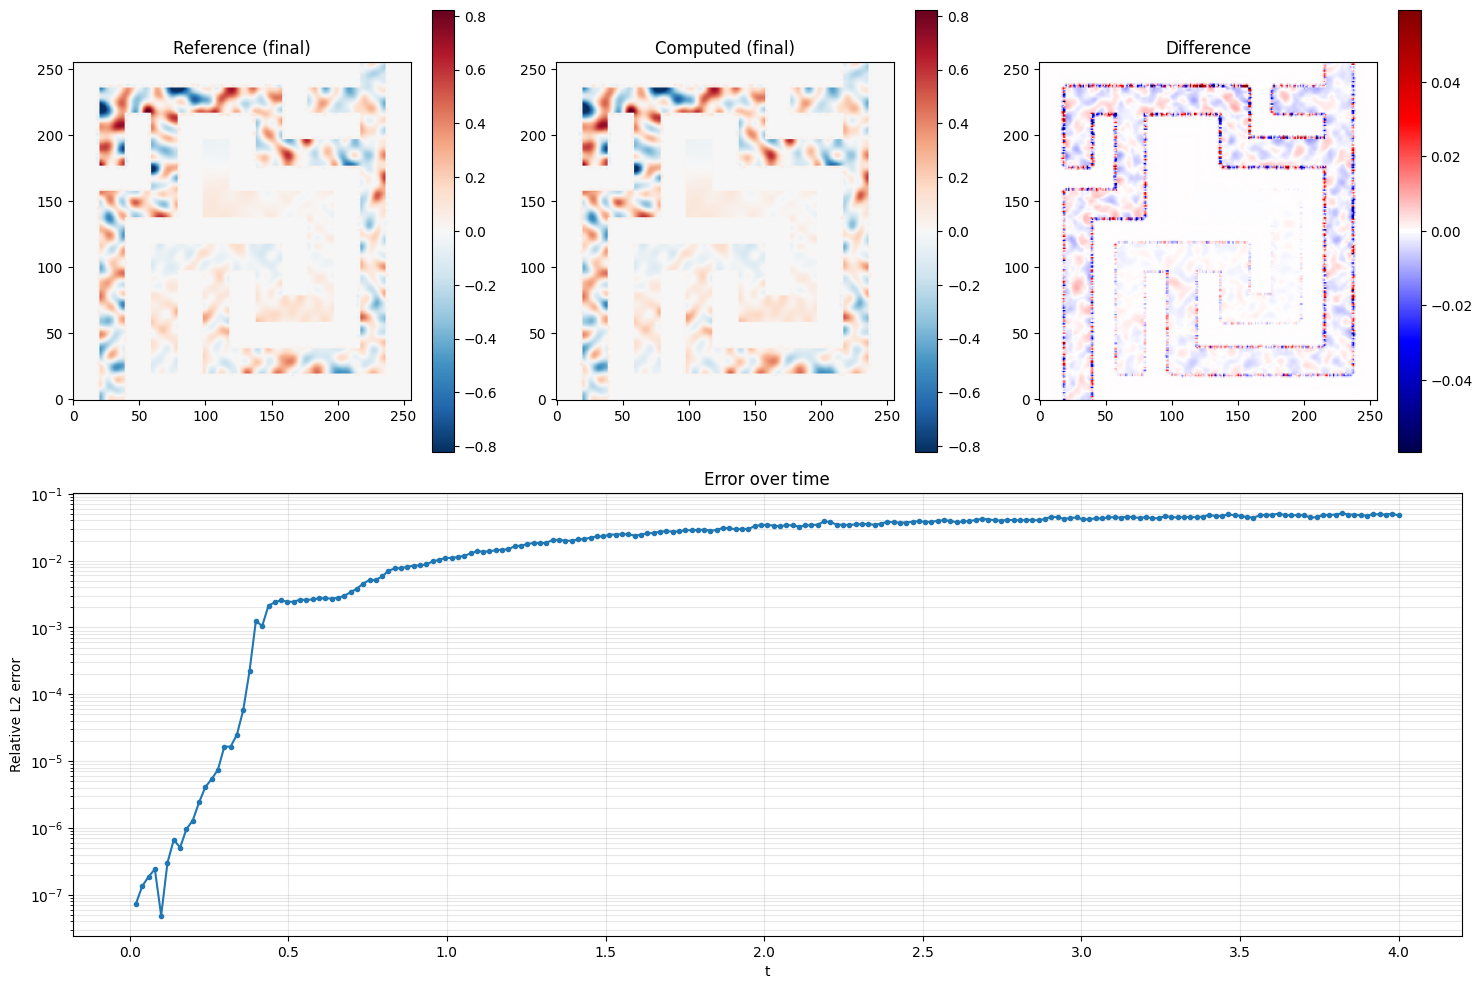

In [4]:
result = solve_sample(sample)
pressure_errors = relative_l2_error(sample["p_ref"], result["p"])
print(f"Final pressure relative L2 error: {pressure_errors[-1]:.6g}")
fig = plot_dashboard(result, sample)
plt.show()


## Variation: anisotropic density

We replace scalar density with $\boldsymbol\rho=\rho\,\mathrm{diag}(a,1/a)$:
$$
 p_t=-K(u_x+v_y),\qquad
 u_t=-\frac{p_x}{a\rho},\qquad
 v_t=-\frac{a}{\rho}p_y.
$$
The isotropic model is recovered at $a=1$. We compare $a=0.5$ and $a=2$, which favor opposite directions, with $c_x=c/\sqrt a$ and $c_y=c\sqrt a$.

This simplified variation is motivated by [Cummer et al., Physical Review Letters (2008)](https://doi.org/10.1103/PhysRevLett.100.024301). We keep the same maze, initial fields, bulk modulus, and boundaries. All models are compared with the same dataset pressure. Since the reference is isotropic, these errors measure agreement with that dataset, rather than validation of anisotropic physics.


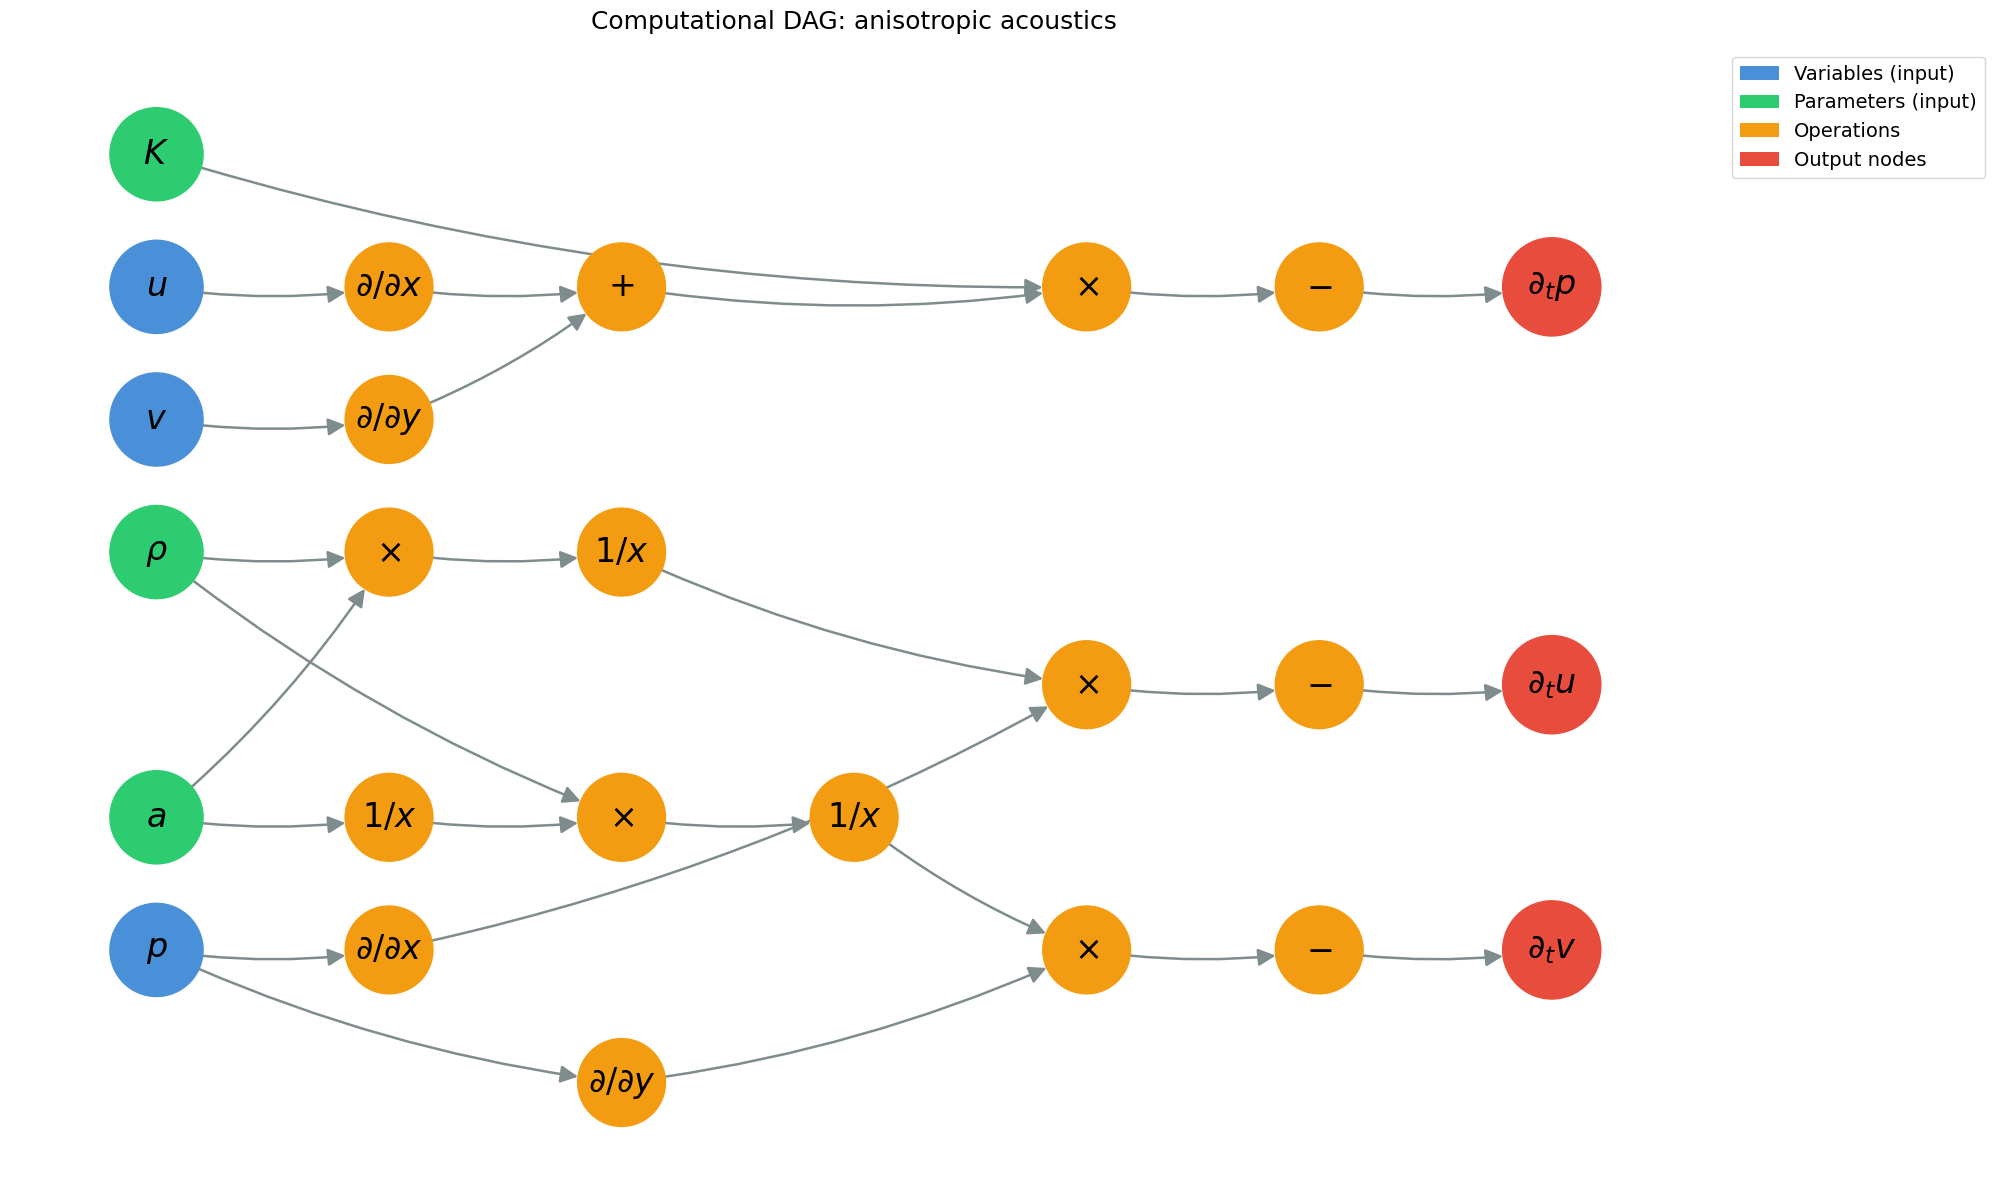

In [2]:
from anisotropy import solve_anisotropic_sample
from anisotropic_acoustic_graph import build_anisotropic_acoustic_graph
from visualization import plot_comparison, plot_reference_errors

anisotropy_coefficients = (0.5, 2.0)
anisotropy = 2.0  # Variant shown in the pressure-field comparison.
anisotropic_graph = build_anisotropic_acoustic_graph()
fig = visualize_graph(anisotropic_graph, title="Computational DAG: anisotropic acoustics")
plt.show()


In [6]:
anisotropic_results = {}
for coefficient in anisotropy_coefficients:
    anisotropic_results[coefficient] = solve_anisotropic_sample(sample, anisotropy=coefficient)
    errors = relative_l2_error(sample["p_ref"], anisotropic_results[coefficient]["p"])
    print(f"a = {coefficient:g}: final pressure relative L2 error = {errors[-1]:.6g}")
anisotropic_result = anisotropic_results[anisotropy]


a = 0.5: final pressure relative L2 error = 1.24292


a = 2: final pressure relative L2 error = 1.20665


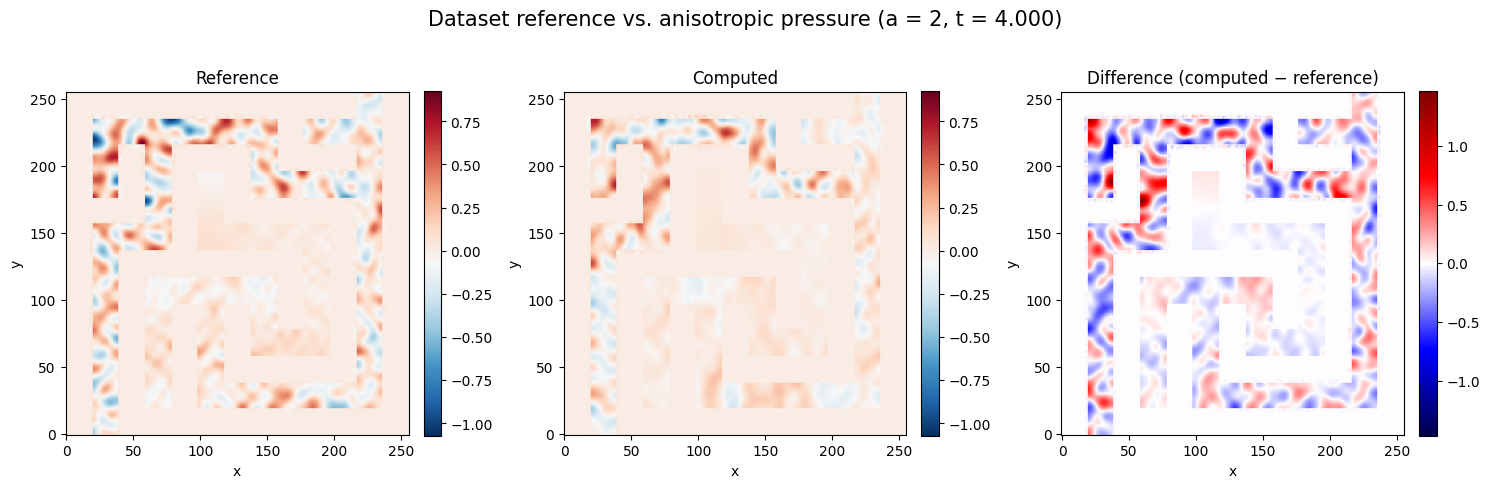

In [7]:
fig = plot_comparison(
    sample["p_ref"][-1], anisotropic_result["p"][-1],
    title=f"Dataset reference vs. anisotropic pressure (a = {anisotropy:g}, t = {sample['times'][-1]:.3f})",
)
plt.show()


## Variation: time-modulated compressibility

We vary compressibility as $\beta(x,y,t)=K_0(x,y)^{-1}b(t)$, where
$$
b(t)=1+\varepsilon\sin(2\pi f t+\phi),\qquad |\varepsilon|<1.
$$
The modified equations are
$$
p_t=-\frac{K_0}{b(t)}(u_x+v_y)-\frac{\dot b(t)}{b(t)}p,\qquad
u_t=-\frac{p_x}{\rho},\qquad v_t=-\frac{p_y}{\rho}.
$$
The additional pressure term accounts for the changing medium; $\Omega=2\pi f$ in the graph. At $\varepsilon=0$ we recover the original equations.

This variation follows the time-dependent compressibility model in [Fleury et al., Nature Communications (2016), equations (3)-(4)](https://www.nature.com/articles/ncomms11744). We keep the same maze, initial fields, and boundaries and compare $\varepsilon=0.1$ and $0.2$ at $f=1$, $\phi=0$. The dataset reference has static compressibility, so these comparisons show how the modification changes agreement with the original data.


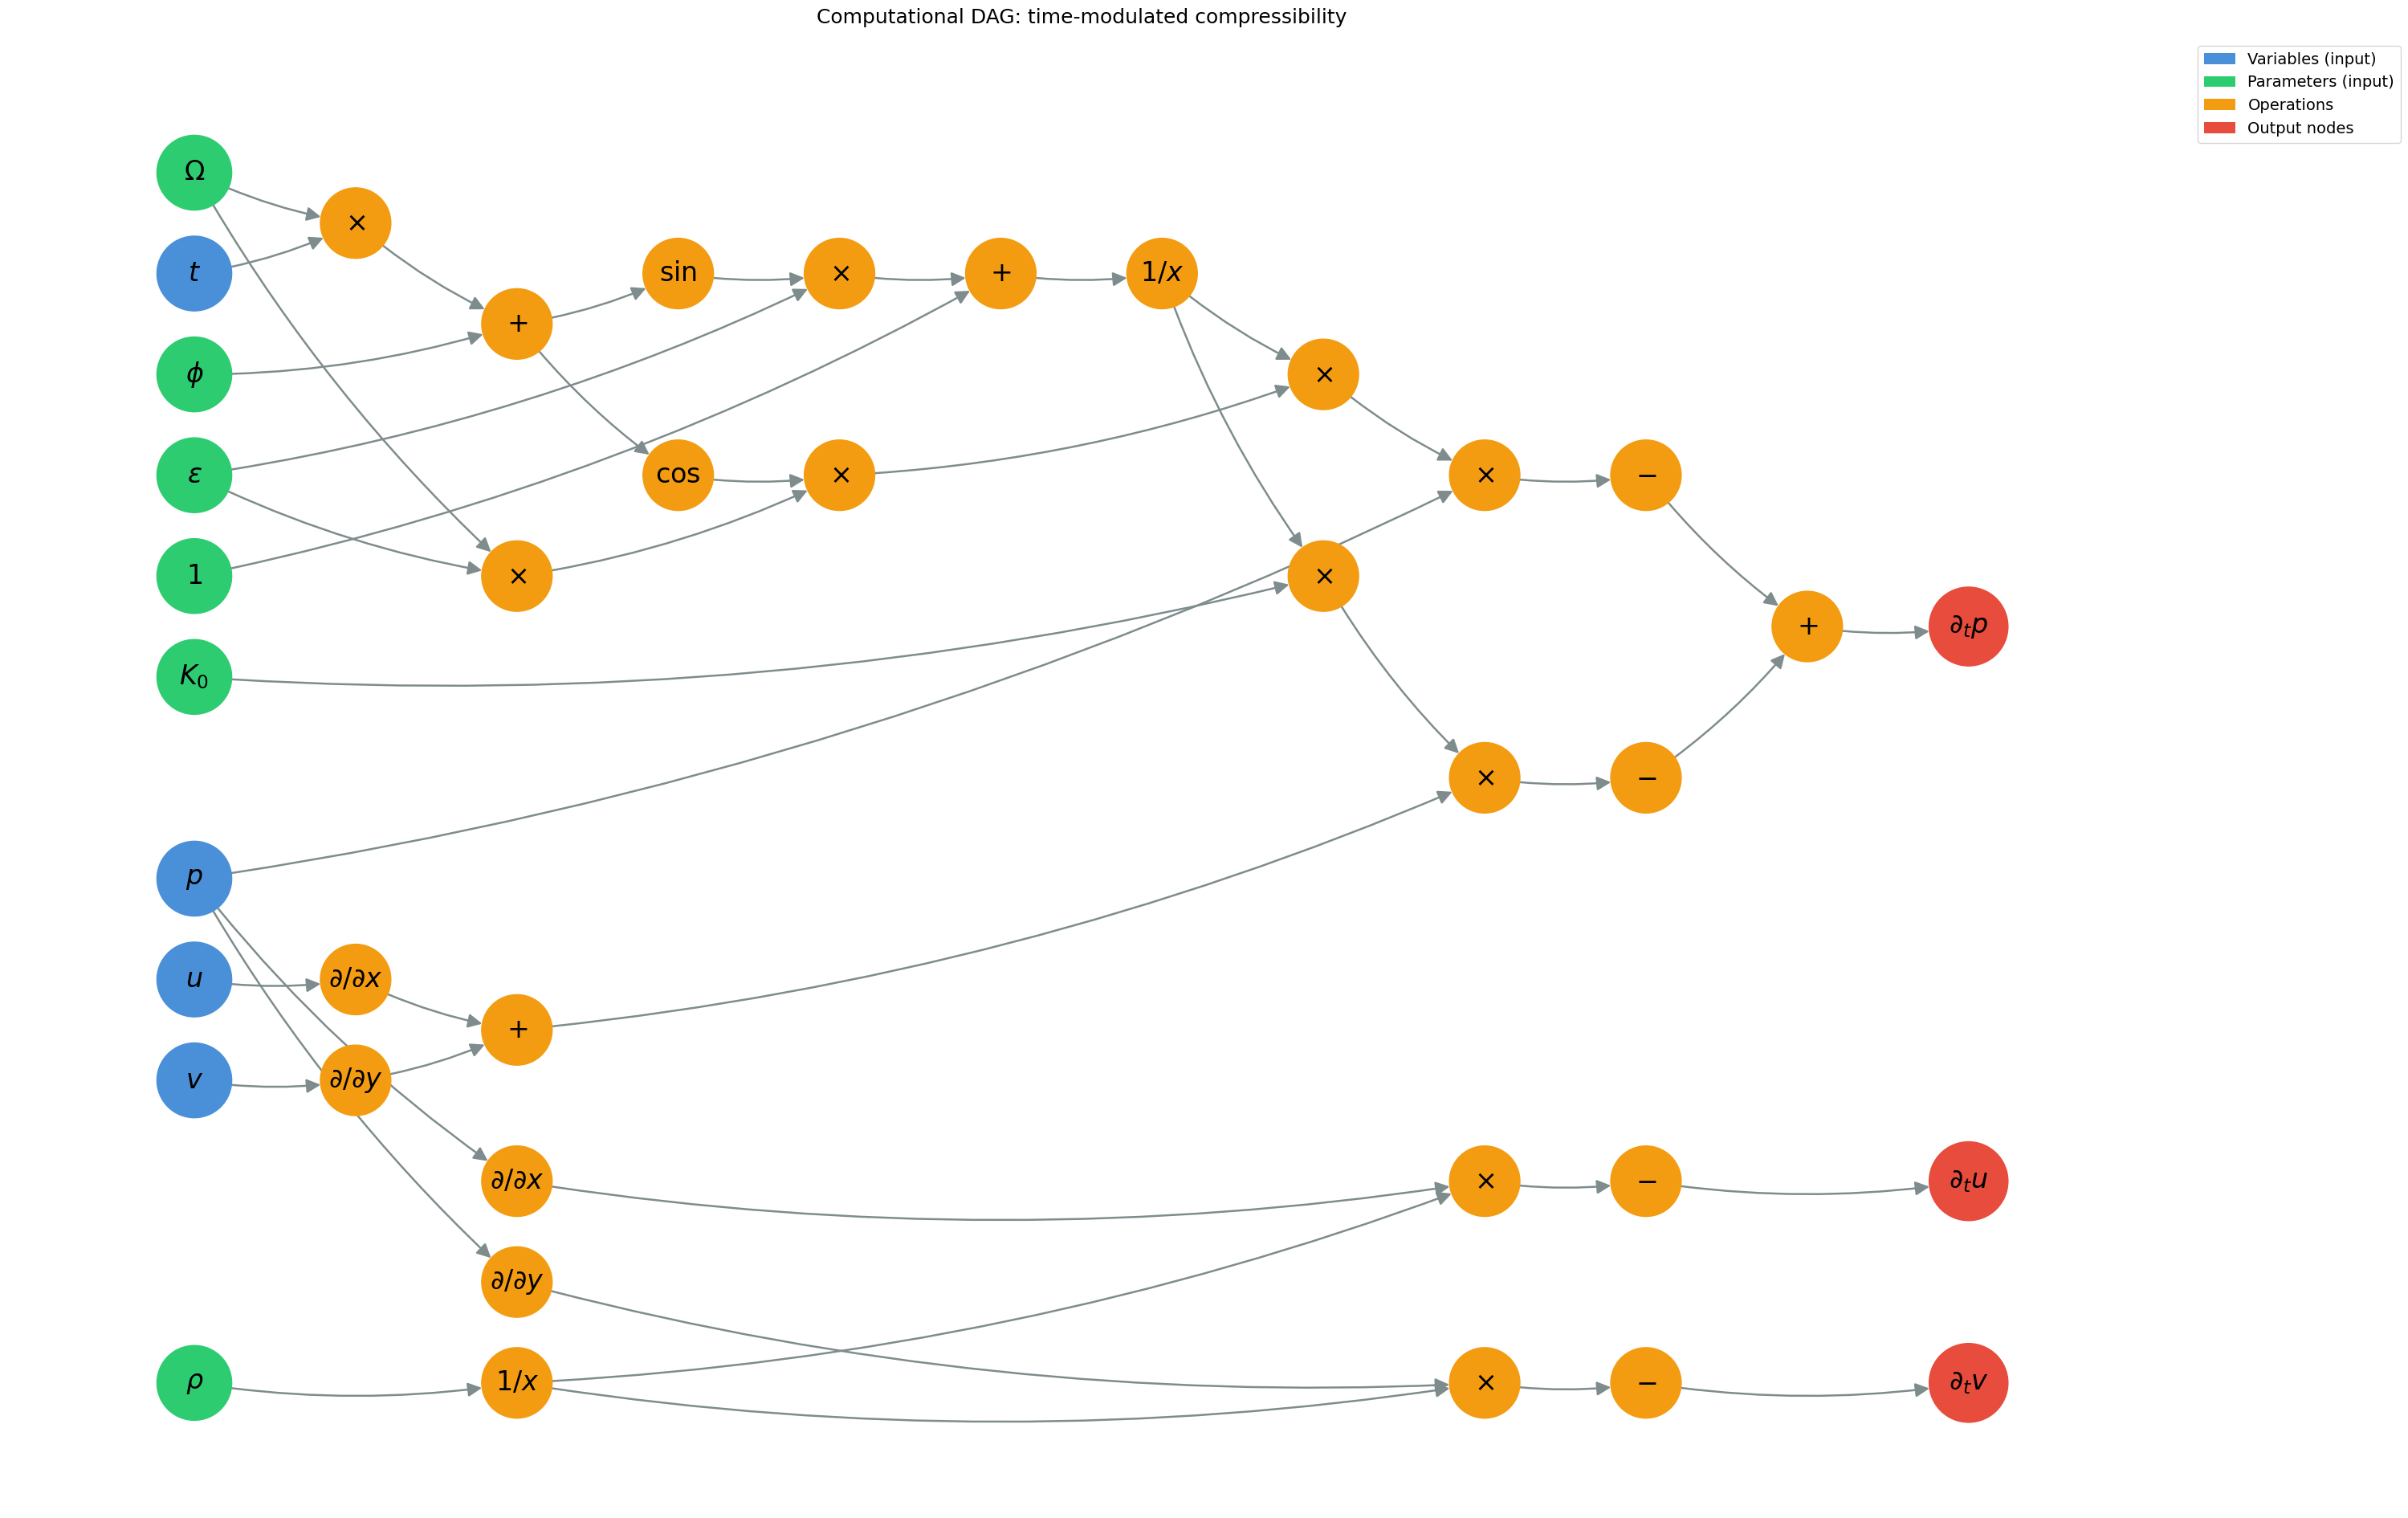

In [3]:
from compressibility import solve_modulated_sample
from modulated_acoustic_graph import build_modulated_acoustic_graph
from visualization import plot_reference_adequacy
from metrics import align_trajectory, coefficient_of_determination, maze_path_mask

modulation_amplitudes = (0.1, 0.2)
modulation_frequency = 1.0
modulation_phase = 0.0
modulation_amplitude = 0.2
modulated_graph = build_modulated_acoustic_graph()
fig = visualize_graph(modulated_graph, figsize=(30, 19), title="Computational DAG: time-modulated compressibility")
plt.show()


In [9]:
modulated_results = {}
for amplitude in modulation_amplitudes:
    modulated_results[amplitude] = solve_modulated_sample(
        sample, amplitude=amplitude, frequency=modulation_frequency, phase=modulation_phase,
    )
    errors = relative_l2_error(sample["p_ref"], modulated_results[amplitude]["p"])
    print(f"epsilon = {amplitude:g}, f = {modulation_frequency:g}: final pressure relative L2 error = {errors[-1]:.6g}")
modulated_result = modulated_results[modulation_amplitude]


epsilon = 0.1, f = 1: final pressure relative L2 error = 0.315914


epsilon = 0.2, f = 1: final pressure relative L2 error = 1.0204


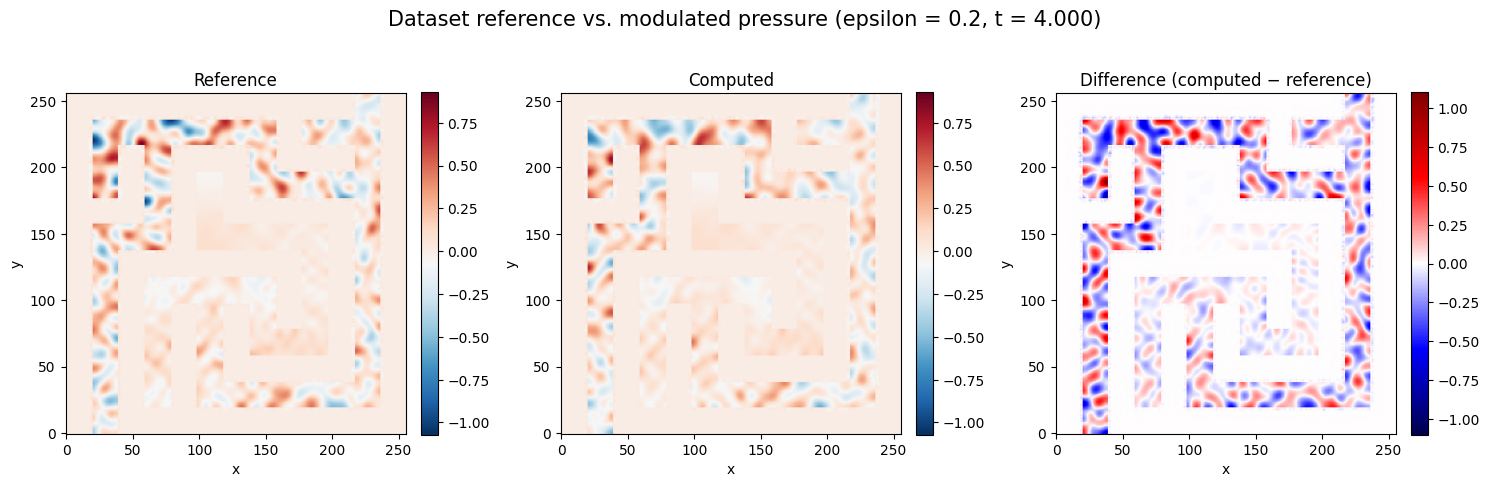

In [10]:
fig = plot_comparison(
    sample["p_ref"][-1], modulated_result["p"][-1],
    title=f"Dataset reference vs. modulated pressure (epsilon = {modulation_amplitude:g}, t = {sample['times'][-1]:.3f})",
)
plt.show()


### Comparison with the dataset
All curves use the same reference and timestamps. Relative L2 error is evaluated per frame; the table reports its final value and R² over the complete pressure trajectory (all times and grid cells).

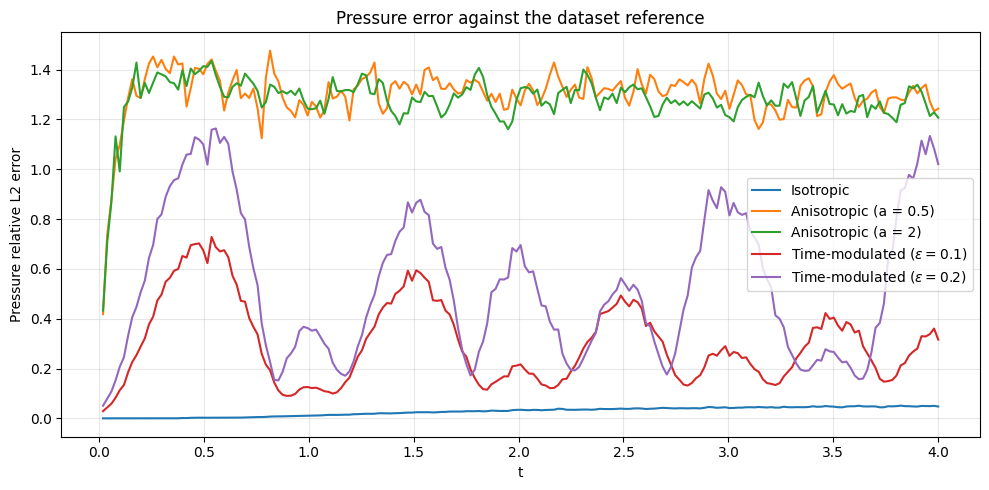

In [11]:
models = {"Isotropic": result}
models.update({f"Anisotropic (a = {a:g})": solution
               for a, solution in anisotropic_results.items()})
models.update({rf"Time-modulated ($\varepsilon = {epsilon:g}$)": solution
               for epsilon, solution in modulated_results.items()})
fig = plot_reference_errors(models, sample)
plt.show()


| Model | Final relative L2 error | Trajectory R² |
|:---|---:|---:|
| Isotropic | 0.04748 | 0.999070 |
| Anisotropic (a = 0.5) | 1.24292 | -0.714540 |
| Anisotropic (a = 2) | 1.20665 | -0.659289 |
| Time-modulated ($\varepsilon = 0.1$) | 0.31591 | 0.875087 |
| Time-modulated ($\varepsilon = 0.2$) | 1.02040 | 0.625184 |

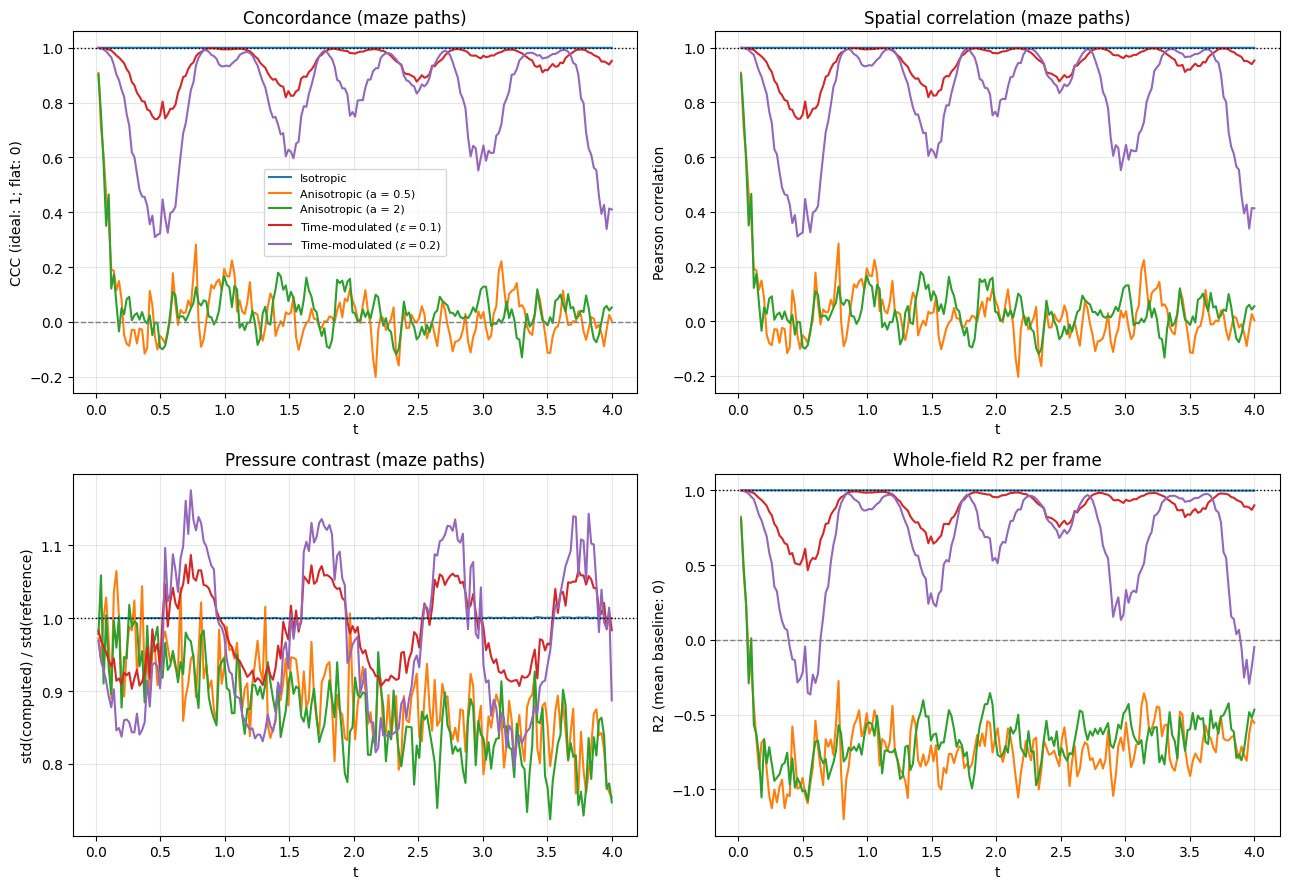

In [12]:
from IPython.display import Markdown, display

rows = ["| Model | Final relative L2 error | Trajectory R² |",
        "|:---|---:|---:|"]
for label, solution in models.items():
    pressure = align_trajectory(solution["p"], solution["t"], sample["times"])
    final_error = relative_l2_error(sample["p_ref"], pressure)[-1]
    r2 = coefficient_of_determination(sample["p_ref"], pressure)
    rows.append(f"| {label} | {final_error:.5f} | {r2:.6f} |")
display(Markdown("\n".join(rows)))

fig = plot_reference_adequacy(models, sample, mask=maze_path_mask(sample["rho"]))
plt.show()


The corrected isotropic baseline closely matches the reference: trajectory $R^2=0.99907$ and final relative L2 error $0.04748$. The previous negative score came primarily from using a domain about half the physical width, compounded by different CFL settings. Time modulation lowers agreement ($R^2=0.87509$ and $0.62518$); the two anisotropic cases remain negative because they strongly change wave propagation. These comparisons measure agreement with the original isotropic dataset, not validation of modified-model physics.

## Additional dataset: CNO/RPB wave benchmark

The [CNO Representative PDE Benchmarks](https://zenodo.org/records/10406879) provide an independent, fully specified wave problem. We use three published out-of-distribution test cases (0, 1, 2). On $[0,1]^2$, $c=0.1$, $p_t(0)=0$, and $p=0$ on every boundary. These are **zero-pressure boundaries**, not the maze's reflective-velocity walls; no absorbing layer is required.

The [published exact solution, Appendix C.3.2](https://arxiv.org/html/2302.01178v2) has the form
$$
p(x,y,t)=\sum_{i,j=1}^{32}A_{ij}\sin(\pi i x)\sin(\pi j y)\cos\!\left(0.1\pi t\sqrt{i^2+j^2}\right).
$$
The stored input is sampled at 64 equally spaced nodes including the endpoints; the stored output is at $t=5$. We recover its sine coefficients and independently check the exact formula against that output. All fields retain their original amplitudes.

For comparison, we evaluate this **analytic reference** at 50 times from 0.1 to 5 as exact cell averages on a $128\times128$ finite-volume grid. Intermediate frames are exact evaluations, not additional stored observations. We set $\rho=1$, $K=0.01$ and initial particle velocities to zero. An odd extension to a doubled periodic square enforces zero pressure at the original edges for every model. The same coefficients as in the maze experiment are used: $a=0.5,2$ and $\varepsilon=0.1,0.2$, with $f=1$, $\phi=0$.


In [14]:
from cno_wave import load_cno_wave, solve_cno_models

cno_samples = [load_cno_wave(i) for i in (0, 1, 2)]
cno_results = []
for cno_sample in cno_samples:
    print(f"CNO test case {cno_sample['sample_idx']}: stored endpoint verification "
          f"relative error = {cno_sample['published_endpoint_error']:.3e}")
    cno_results.append(solve_cno_models(cno_sample))


CNO test case 0: stored endpoint verification relative error = 3.413e-15


CNO test case 1: stored endpoint verification relative error = 3.369e-15


CNO test case 2: stored endpoint verification relative error = 3.546e-15


In [15]:
from IPython.display import Markdown, display

cno_rows = ["| Case | Model | Final relative L2 error | Trajectory R² |",
            "|---:|:---|---:|---:|"]
for cno_sample, case_models in zip(cno_samples, cno_results):
    for label, solution in case_models.items():
        pressure = align_trajectory(solution["p"], solution["t"], cno_sample["times"])
        final_error = relative_l2_error(cno_sample["p_ref"], pressure)[-1]
        r2 = coefficient_of_determination(cno_sample["p_ref"], pressure)
        cno_rows.append(f"| {cno_sample['sample_idx']} | {label} | {final_error:.5f} | {r2:.6f} |")
display(Markdown("\n".join(cno_rows)))


| Case | Model | Final relative L2 error | Trajectory R² |
|---:|:---|---:|---:|
| 0 | Isotropic | 0.08896 | 0.996292 |
| 0 | Anisotropic (a = 0.5) | 1.20796 | 0.216559 |
| 0 | Anisotropic (a = 2) | 0.92029 | 0.314987 |
| 0 | Time-modulated ($\varepsilon = 0.1$) | 0.13939 | 0.986784 |
| 0 | Time-modulated ($\varepsilon = 0.2$) | 0.19646 | 0.963203 |
| 1 | Isotropic | 0.07783 | 0.997387 |
| 1 | Anisotropic (a = 0.5) | 0.87590 | 0.538238 |
| 1 | Anisotropic (a = 2) | 0.92871 | 0.402542 |
| 1 | Time-modulated ($\varepsilon = 0.1$) | 0.11903 | 0.988787 |
| 1 | Time-modulated ($\varepsilon = 0.2$) | 0.17082 | 0.965198 |
| 2 | Isotropic | 0.06898 | 0.997541 |
| 2 | Anisotropic (a = 0.5) | 0.97555 | 0.348802 |
| 2 | Anisotropic (a = 2) | 1.14885 | 0.328531 |
| 2 | Time-modulated ($\varepsilon = 0.1$) | 0.10537 | 0.989262 |
| 2 | Time-modulated ($\varepsilon = 0.2$) | 0.14853 | 0.966701 |

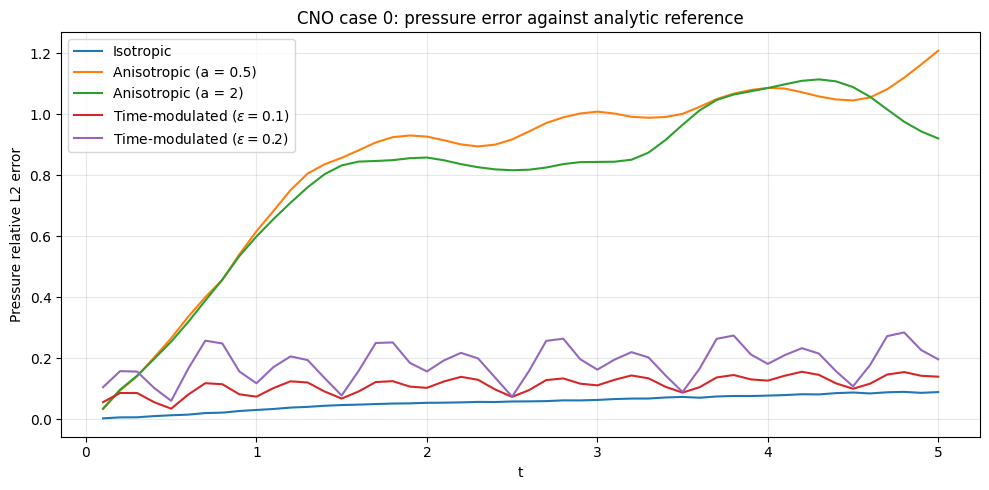

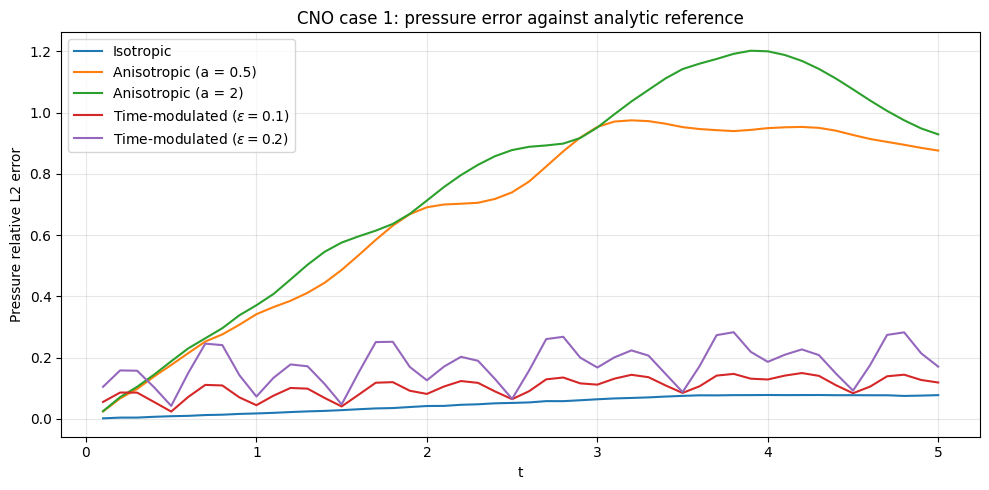

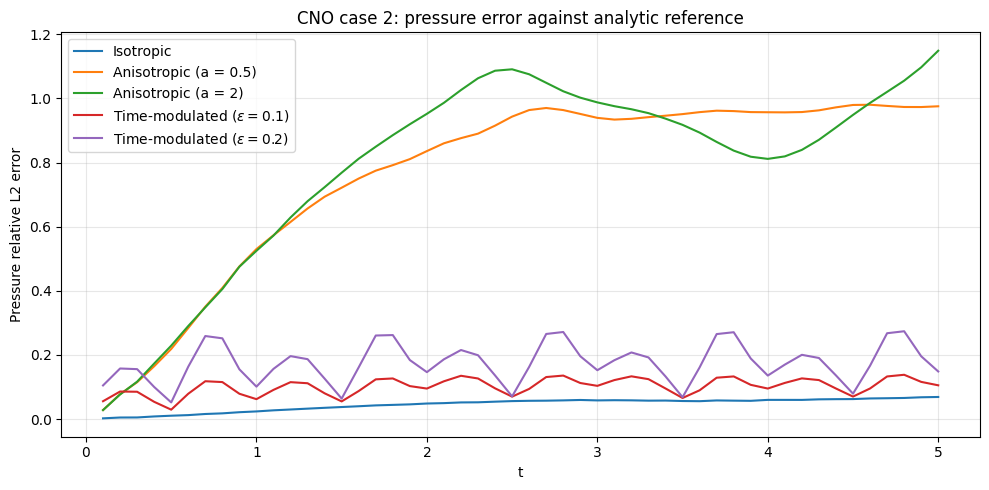

In [16]:
for cno_sample, case_models in zip(cno_samples, cno_results):
    fig = plot_reference_errors(case_models, cno_sample)
    fig.axes[0].set_title(f"CNO case {cno_sample['sample_idx']}: pressure error against analytic reference")
    plt.show()


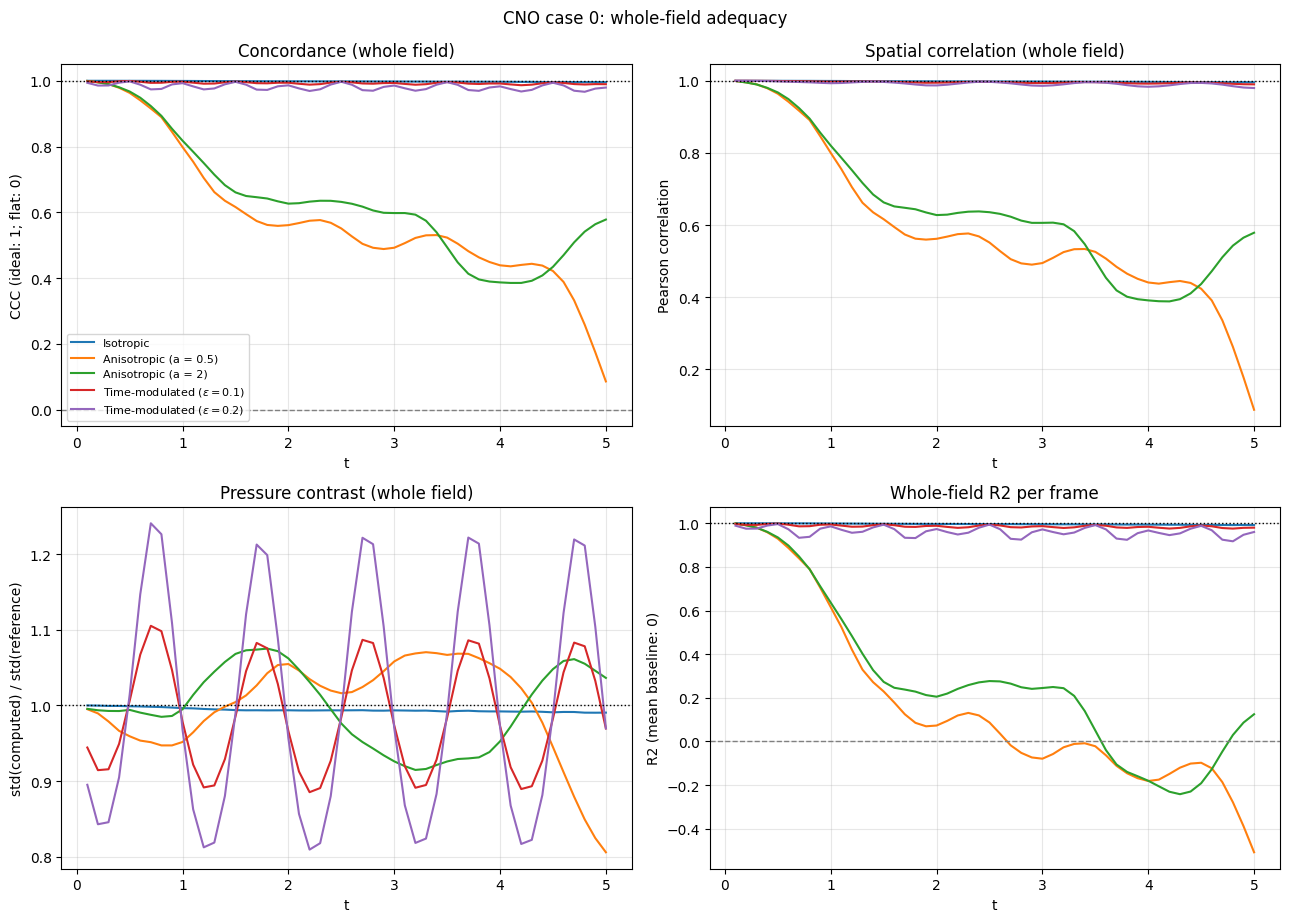

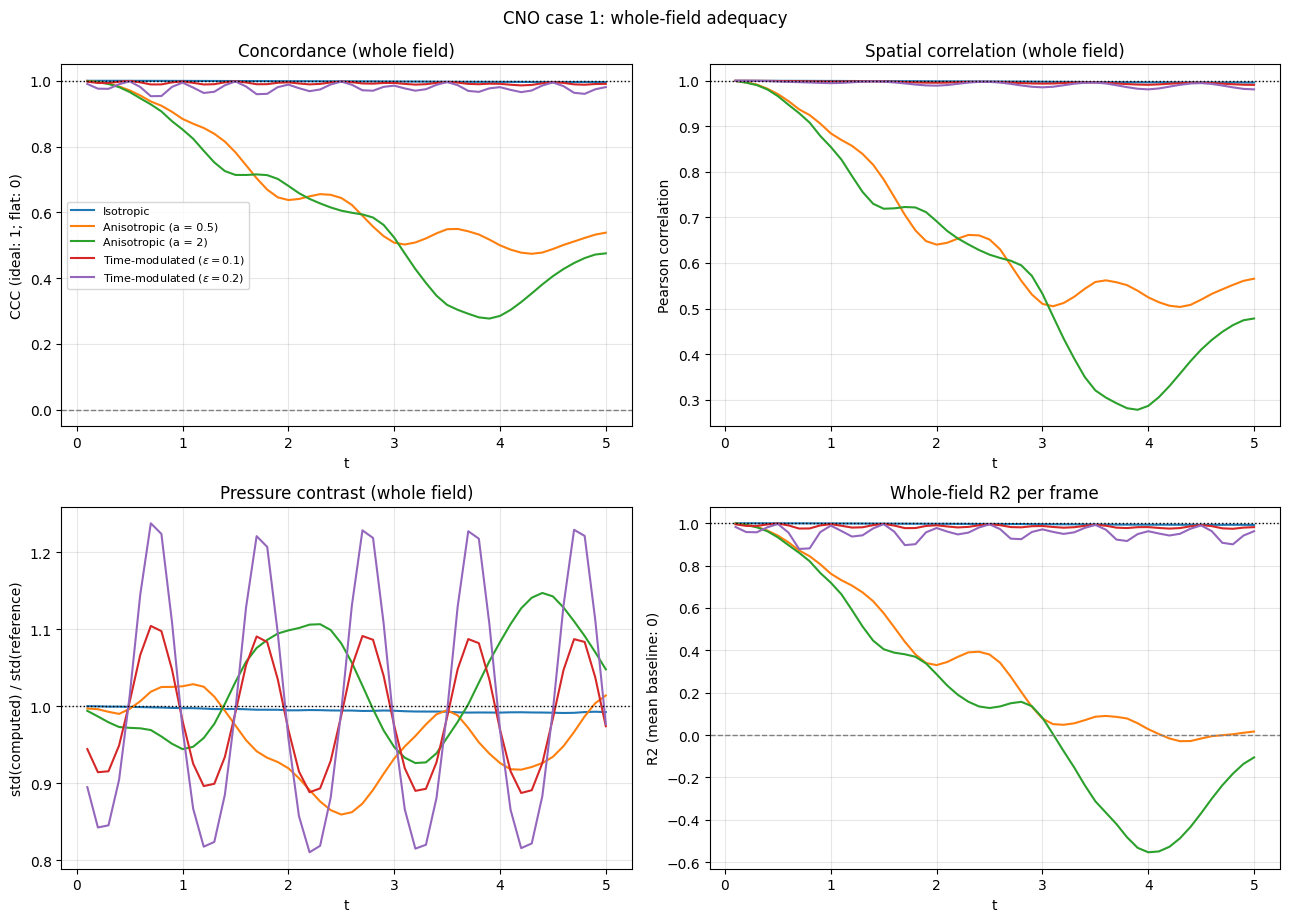

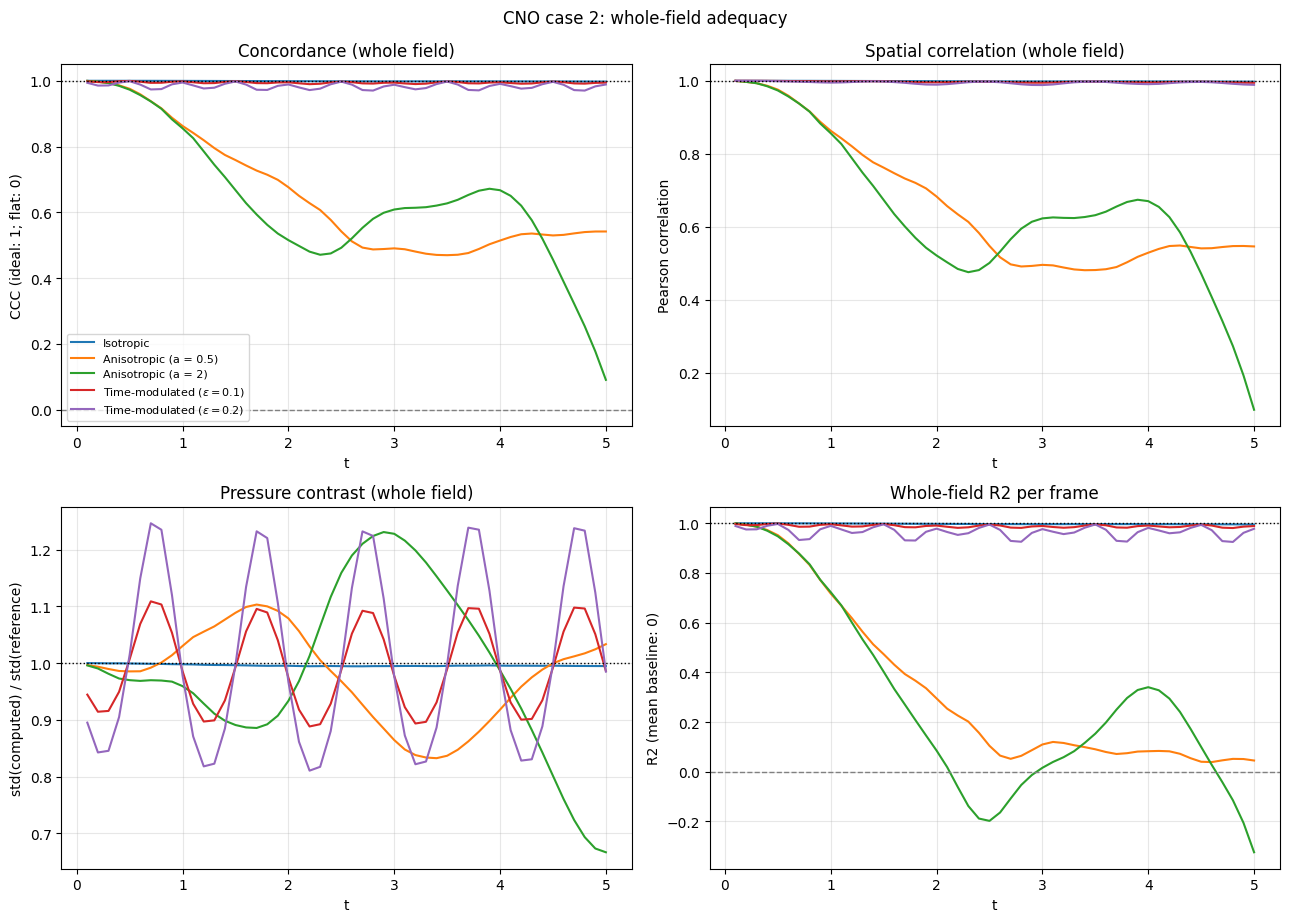

In [17]:
for cno_sample, case_models in zip(cno_samples, cno_results):
    fig = plot_reference_adequacy(case_models, cno_sample)
    fig.suptitle(f"CNO case {cno_sample['sample_idx']}: whole-field adequacy", y=1.02)
    plt.show()


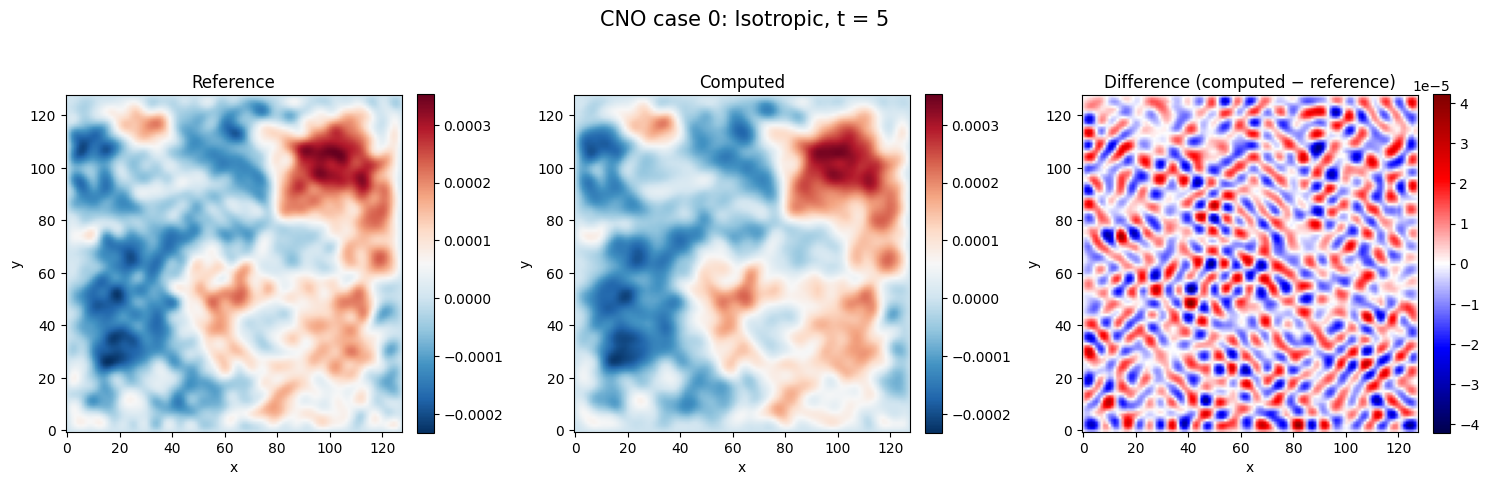

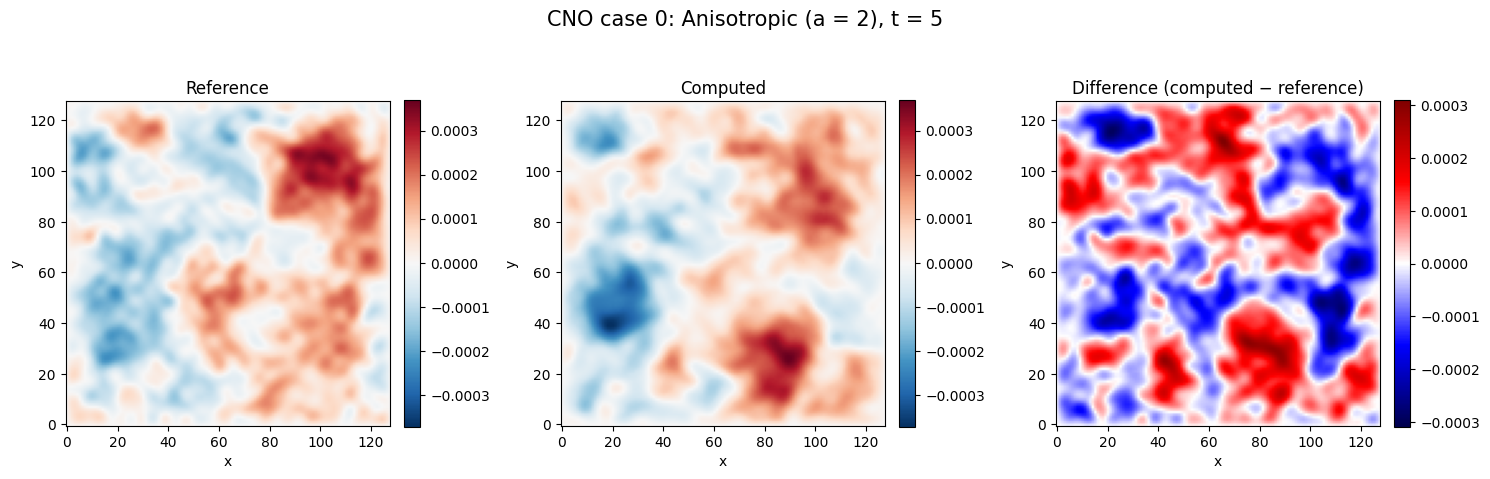

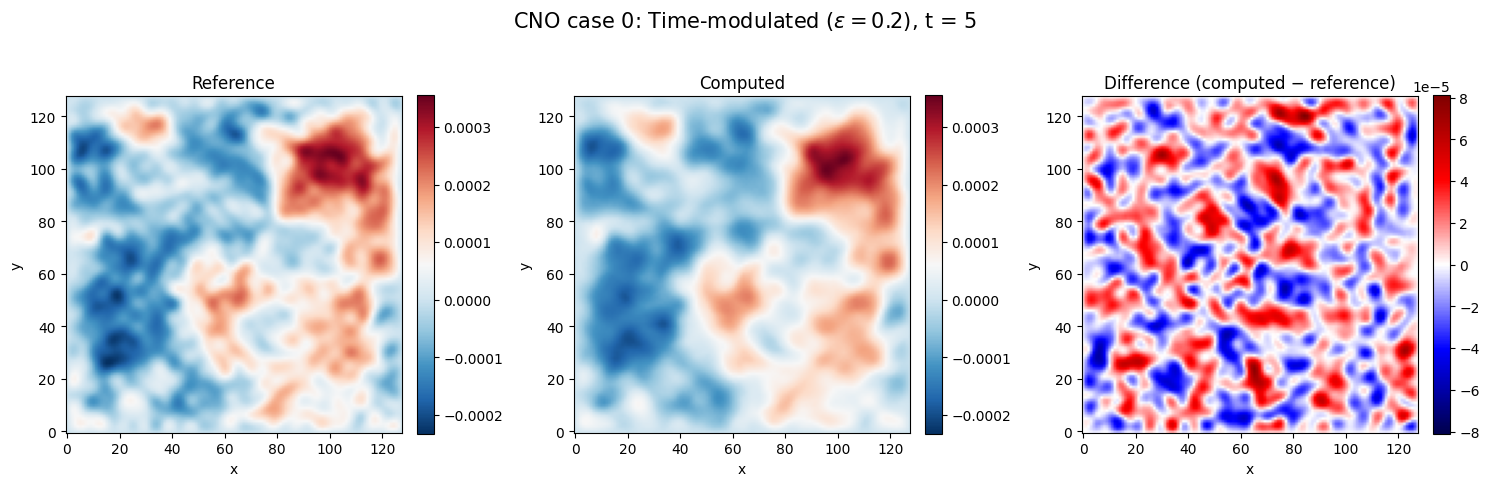

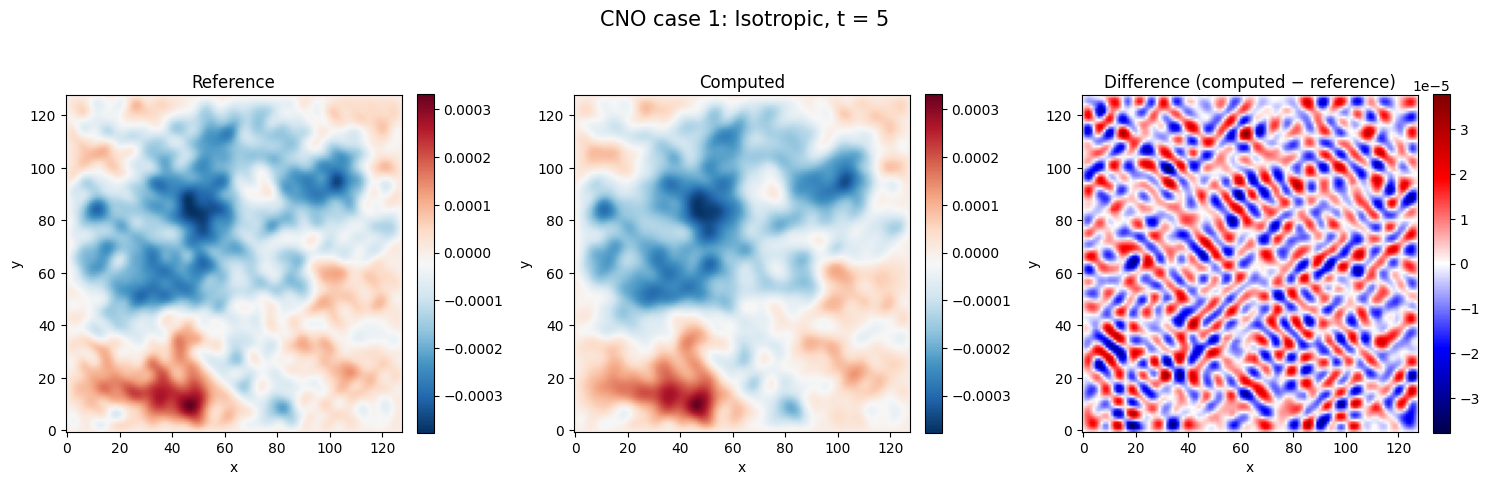

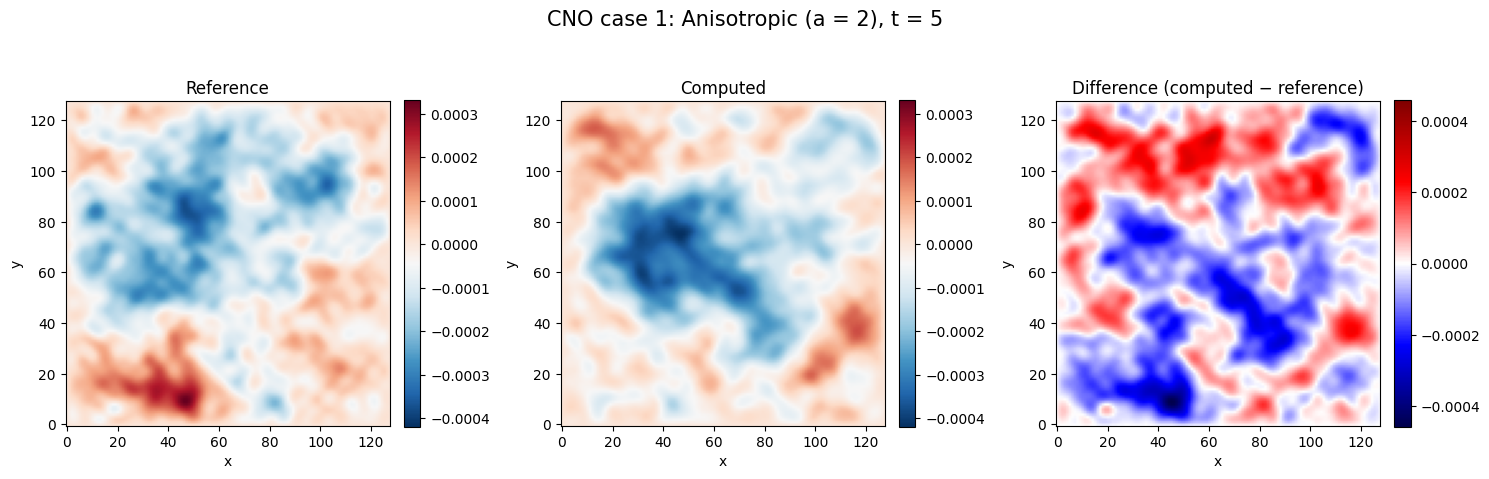

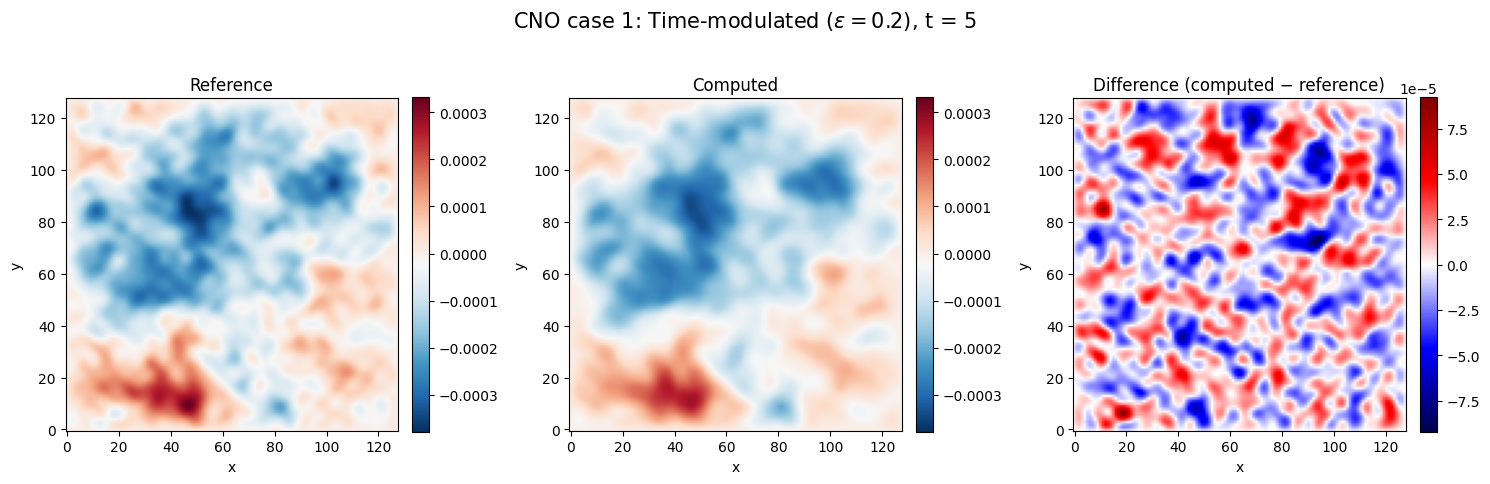

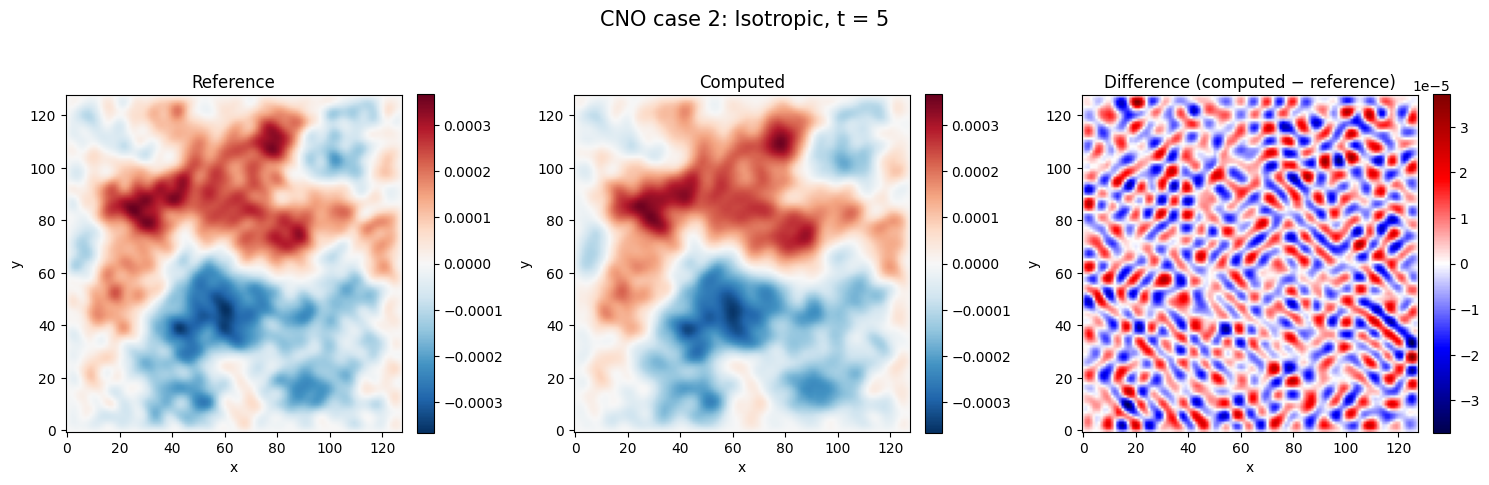

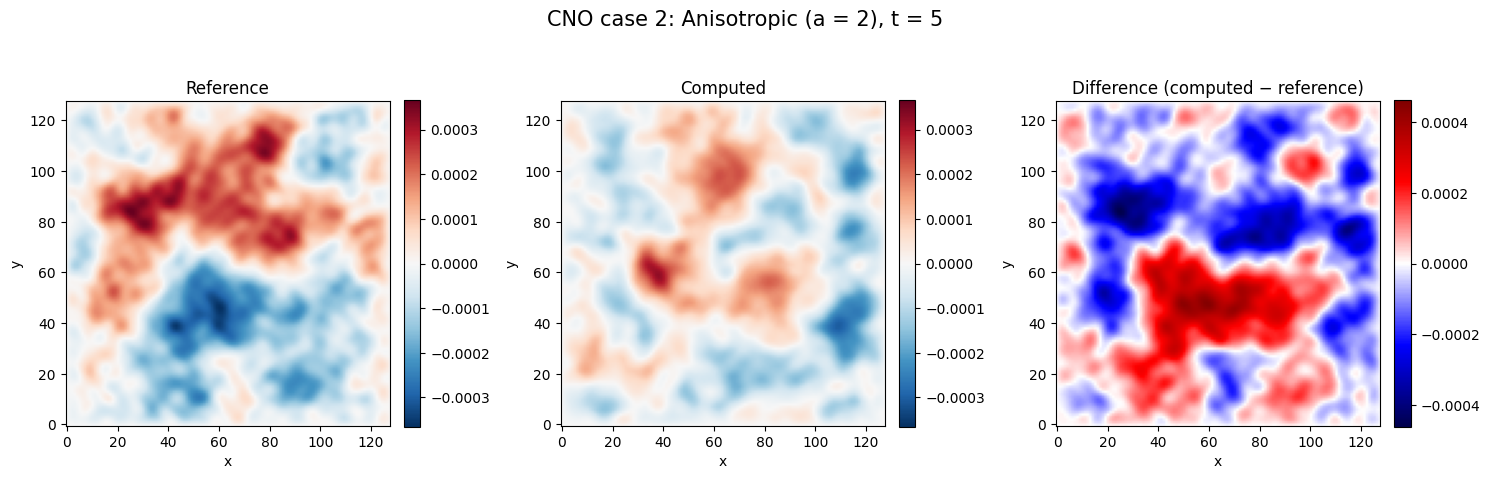

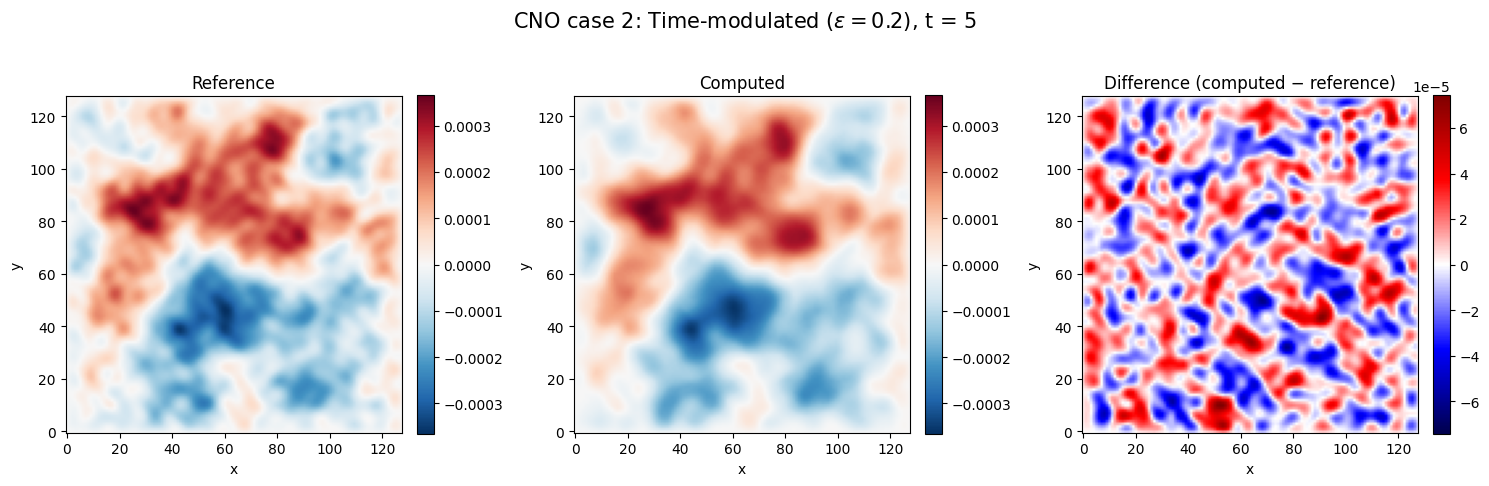

In [18]:
for cno_sample, case_models in zip(cno_samples, cno_results):
    for label in ("Isotropic", "Anisotropic (a = 2)", r"Time-modulated ($\varepsilon = 0.2$)"):
        fig = plot_comparison(cno_sample["p_ref"][-1], case_models[label]["p"][-1],
                              title=f"CNO case {cno_sample['sample_idx']}: {label}, t = 5")
        plt.show()


Across all three cases, the isotropic baseline agrees best with the reference: trajectory $R^2=0.9963$–$0.9975$ and final relative L2 error $0.069$–$0.089$. Time modulation reduces agreement, with the smaller amplitude closer to the reference. Anisotropy changes the spatial pattern much more strongly. These results complement the maze experiment with a homogeneous medium and fully specified zero-pressure boundaries; the references still describe isotropic, static physics.